In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [4]:
uploaded = files.upload()

Saving cleaned_ad_data.csv to cleaned_ad_data (1).csv


In [6]:
df = pd.read_csv("cleaned_ad_data.csv")

df["date"] = pd.to_datetime(df["date"])

numeric_columns = [
    "spend",
    "impressions",
    "clicks",
    "conversions"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna()
df = df.sort_values(["date", "channel"])

print("Rows:", len(df))
print("Dates:", df["date"].nunique())
print("Channels:", df["channel"].unique())
print(df.head())

Rows: 63
Dates: 21
Channels: ['Display' 'Search' 'Social']
        date  channel   spend  impressions  clicks  conversions
2 2026-01-01  Display  212.55        42509     350           10
0 2026-01-01   Search  511.15        18255     908           76
1 2026-01-01   Social  286.71        28671     600           41
5 2026-01-02  Display  201.44        40287     342           10
3 2026-01-02   Search  462.38        16513     857           77


In [8]:
df["CTR"] = df["clicks"] / df["impressions"]
df["CVR"] = df["conversions"] / df["clicks"]
df["CPA"] = df["spend"] / df["conversions"]

performance = df.groupby("channel").agg(
    total_spend=("spend", "sum"),
    total_impressions=("impressions", "sum"),
    total_clicks=("clicks", "sum"),
    total_conversions=("conversions", "sum")
)

performance["CTR"] = (
    performance["total_clicks"] /
    performance["total_impressions"]
)

performance["CVR"] = (
    performance["total_conversions"] /
    performance["total_clicks"]
)

performance["CPA"] = (
    performance["total_spend"] /
    performance["total_conversions"]
)

performance

,total_spend,total_impressions,total_clicks,total_conversions,CTR,CVR,CPA
channel,,,,,,,
Display,4282.12,856415,7451,212,0.008700,0.028453,20.198679
Search,10471.81,373983,20395,1906,0.054535,0.093454,5.494129
Social,6299.65,629960,12303,764,0.019530,0.062099,8.245615


In [9]:
system_prompt = """
You are an advertising budget optimization agent.

Your goal is to allocate a fixed daily budget across Search, Social,
and Display to maximize expected conversions.

Use historical conversion efficiency to identify the strongest and
weakest channels. Increase the strongest channel's budget and reduce
the weakest channel's budget.

Guardrails:
1. Keep at least 15% of the total budget in every channel.
2. Limit each channel's daily budget change to 20%.
3. Never allocate zero dollars to a channel.
4. Use only previous performance data when making a new decision.
5. Log the reason for every budget change.
"""

print(system_prompt)


You are an advertising budget optimization agent.

Your goal is to allocate a fixed daily budget across Search, Social,
and Display to maximize expected conversions.

Use historical conversion efficiency to identify the strongest and
weakest channels. Increase the strongest channel's budget and reduce
the weakest channel's budget.

Guardrails:
1. Keep at least 15% of the total budget in every channel.
2. Limit each channel's daily budget change to 20%.
3. Never allocate zero dollars to a channel.
4. Use only previous performance data when making a new decision.
5. Log the reason for every budget change.



In [10]:
def decide_budget(history, previous_budget, total_budget=1000):
    channels = list(previous_budget.keys())
    minimum_budget = total_budget * 0.15

    # Start equally if there is no previous performance data
    if history.empty:
        return previous_budget.copy(), "Started with an equal budget split."

    history = history.copy()
    history["conversions_per_dollar"] = (
        history["conversions"] / history["spend"]
    )

    scores = history.groupby("channel")["conversions_per_dollar"].sum()

    best_channel = scores.idxmax()
    worst_channel = scores.idxmin()

    new_budget = previous_budget.copy()

    # Move 10% of the total budget, while respecting guardrails
    planned_shift = total_budget * 0.10

    max_shift_for_best = previous_budget[best_channel] * 0.20
    max_shift_from_worst = previous_budget[worst_channel] * 0.20

    available_from_worst = (
        previous_budget[worst_channel] - minimum_budget
    )

    shift = min(
        planned_shift,
        max_shift_for_best,
        max_shift_from_worst,
        available_from_worst
    )

    shift = max(0, shift)

    if shift > 0 and best_channel != worst_channel:
        new_budget[best_channel] += shift
        new_budget[worst_channel] -= shift

        reason = (
            f"Increased {best_channel} by ${shift:.2f} because it had "
            f"the highest conversion efficiency. Reduced {worst_channel} "
            f"by ${shift:.2f}. Minimum budget and daily change limits "
            f"were applied."
        )
    else:
        reason = "Budget remained stable because guardrails prevented a shift."

    return new_budget, reason

In [11]:
total_daily_budget = 1000
channels = sorted(df["channel"].unique())

equal_budget = {
    channel: total_daily_budget / len(channels)
    for channel in channels
}

agent_budget = equal_budget.copy()
history = pd.DataFrame()

decision_log = []
agent_results = []
baseline_results = []

for current_date in sorted(df["date"].unique()):

    daily_data = df[df["date"] == current_date].copy()

    # Use the day's actual channel efficiency as the simulation environment
    daily_data["conversions_per_dollar"] = (
        daily_data["conversions"] / daily_data["spend"]
    )

    efficiency = daily_data.set_index("channel")[
        "conversions_per_dollar"
    ].to_dict()

    # Estimate conversions under the agent's budget
    agent_conversions = sum(
        agent_budget[channel] * efficiency[channel]
        for channel in channels
    )

    # Estimate conversions under an equal-split baseline
    baseline_conversions = sum(
        equal_budget[channel] * efficiency[channel]
        for channel in channels
    )

    agent_results.append({
        "date": current_date,
        "budget": sum(agent_budget.values()),
        "expected_conversions": agent_conversions
    })

    baseline_results.append({
        "date": current_date,
        "budget": sum(equal_budget.values()),
        "expected_conversions": baseline_conversions
    })

    # Decide the budget for the next day using only current and prior data
    next_budget, reason = decide_budget(
        history,
        agent_budget,
        total_budget=total_daily_budget
    )

    for channel in channels:
        decision_log.append({
            "date": current_date,
            "channel": channel,
            "old_budget": round(agent_budget[channel], 2),
            "new_budget": round(next_budget[channel], 2),
            "reason": reason
        })

    # Current performance becomes available for future decisions
    history = pd.concat([history, daily_data], ignore_index=True)
    agent_budget = next_budget

decision_log_df = pd.DataFrame(decision_log)
agent_results_df = pd.DataFrame(agent_results)
baseline_results_df = pd.DataFrame(baseline_results)

decision_log_df.head()

,date,channel,old_budget,new_budget,reason
0,2026-01-01,Display,333.33,333.33,Started with an equal budget split.
1,2026-01-01,Search,333.33,333.33,Started with an equal budget split.
2,2026-01-01,Social,333.33,333.33,Started with an equal budget split.
3,2026-01-02,Display,333.33,266.67,Increased Search by $66.67 because it had the ...
4,2026-01-02,Search,333.33,400.00,Increased Search by $66.67 because it had the ...


In [12]:
agent_total_conversions = agent_results_df["expected_conversions"].sum()
baseline_total_conversions = baseline_results_df["expected_conversions"].sum()

agent_total_spend = agent_results_df["budget"].sum()
baseline_total_spend = baseline_results_df["budget"].sum()

agent_cpa = agent_total_spend / agent_total_conversions
baseline_cpa = baseline_total_spend / baseline_total_conversions

results = pd.DataFrame({
    "Approach": [
        "Equal Split Baseline",
        "Optimization Agent"
    ],
    "Expected Conversions": [
        baseline_total_conversions,
        agent_total_conversions
    ],
    "Average CPA": [
        baseline_cpa,
        agent_cpa
    ]
})

results

,Approach,Expected Conversions,Average CPA
0,Equal Split Baseline,2471.828069,8.495737
1,Optimization Agent,2914.962424,7.204210


In [13]:
decision_log_df[
    [
        "date",
        "channel",
        "old_budget",
        "new_budget",
        "reason"
    ]
].head(12)

,date,channel,old_budget,new_budget,reason
0,2026-01-01,Display,333.33,333.33,Started with an equal budget split.
1,2026-01-01,Search,333.33,333.33,Started with an equal budget split.
2,2026-01-01,Social,333.33,333.33,Started with an equal budget split.
3,2026-01-02,Display,333.33,266.67,Increased Search by $66.67 because it had the ...
4,2026-01-02,Search,333.33,400.00,Increased Search by $66.67 because it had the ...
5,2026-01-02,Social,333.33,333.33,Increased Search by $66.67 because it had the ...
6,2026-01-03,Display,266.67,213.33,Increased Search by $53.33 because it had the ...
7,2026-01-03,Search,400.00,453.33,Increased Search by $53.33 because it had the ...
8,2026-01-03,Social,333.33,333.33,Increased Search by $53.33 because it had the ...
9,2026-01-04,Display,213.33,170.67,Increased Search by $42.67 because it had the ...


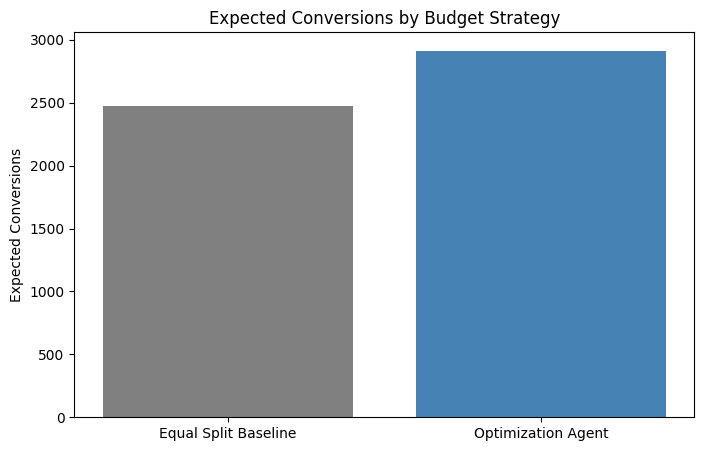

In [14]:
comparison = pd.DataFrame({
    "Approach": ["Equal Split Baseline", "Optimization Agent"],
    "Expected Conversions": [
        baseline_total_conversions,
        agent_total_conversions
    ]
})

plt.figure(figsize=(8, 5))
plt.bar(
    comparison["Approach"],
    comparison["Expected Conversions"],
    color=["gray", "steelblue"]
)

plt.title("Expected Conversions by Budget Strategy")
plt.ylabel("Expected Conversions")
plt.show()

In [15]:
decision_log_df.to_csv("decision_log.csv", index=False)
results.to_csv("evaluation_results.csv", index=False)

print("Saved decision_log.csv and evaluation_results.csv")

Saved decision_log.csv and evaluation_results.csv
